In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("karachi_house.csv")

In [3]:
data.head()

,Unnamed: 0,Address,Price,NoOfBedrooms,NoOfBathrooms,AreaSqYards
0,0,"Bahria Town Karachi, Karachi",4200000.0,1.0,1.0,60
1,1,"Bahria Town - Precinct 17, Bahria Town Karachi",5900000.0,2.0,2.0,161
2,2,"Bahria Paradise, Bahria Town Karachi",42000000.0,5.0,5.0,500
3,3,"Askari 5 - Sector J, Askari 5",37500000.0,3.0,3.0,300
4,4,"Bahria Town - Precinct 35, Bahria Sports City",21000000.0,4.0,4.0,350


In [4]:
data.shape

(16849, 6)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16849 entries, 0 to 16848
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     16849 non-null  int64  
 1   Address        16849 non-null  object 
 2   Price          16849 non-null  float64
 3   NoOfBedrooms   16849 non-null  float64
 4   NoOfBathrooms  16849 non-null  float64
 5   AreaSqYards    16849 non-null  int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 789.9+ KB


In [6]:
data.isna().sum()

Unnamed: 0       0
Address          0
Price            0
NoOfBedrooms     0
NoOfBathrooms    0
AreaSqYards      0
dtype: int64

In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
data.columns = ['Unnamed', 'Address', 'Price', 'NoOfBedrooms', 'NoOfBathrooms',
       'AreaSqYards']

In [9]:
data.Unnamed.unique()

array([    0,     1,     2, ..., 19447, 19448, 19449])

In [10]:
data = data.drop(columns=["Unnamed"])

In [11]:
data.head()

,Address,Price,NoOfBedrooms,NoOfBathrooms,AreaSqYards
0,"Bahria Town Karachi, Karachi",4200000.0,1.0,1.0,60
1,"Bahria Town - Precinct 17, Bahria Town Karachi",5900000.0,2.0,2.0,161
2,"Bahria Paradise, Bahria Town Karachi",42000000.0,5.0,5.0,500
3,"Askari 5 - Sector J, Askari 5",37500000.0,3.0,3.0,300
4,"Bahria Town - Precinct 35, Bahria Sports City",21000000.0,4.0,4.0,350


In [12]:
data.duplicated().sum()

np.int64(7706)

In [13]:
dup = data[data.duplicated(keep=False)]

In [14]:
dup.shape

(10765, 5)

In [15]:
dup.sort_values(["Address" , "Price"]).head(10)

,Address,Price,NoOfBedrooms,NoOfBathrooms,AreaSqYards
8665,"ARY Laguna, DHA City Karachi",5750000.0,1.0,1.0,61
8717,"ARY Laguna, DHA City Karachi",5750000.0,1.0,1.0,61
8667,"ARY Laguna, DHA City Karachi",8500000.0,2.0,2.0,94
8719,"ARY Laguna, DHA City Karachi",8500000.0,2.0,2.0,94
12777,"ARY Laguna, DHA City Karachi",9550000.0,2.0,2.0,114
12835,"ARY Laguna, DHA City Karachi",9550000.0,2.0,2.0,114
8666,"ARY Laguna, DHA City Karachi",10800000.0,2.0,2.0,114
8718,"ARY Laguna, DHA City Karachi",10800000.0,2.0,2.0,114
8668,"ARY Laguna, DHA City Karachi",14500000.0,3.0,3.0,161
8720,"ARY Laguna, DHA City Karachi",14500000.0,3.0,3.0,161


In [16]:
data = data.drop_duplicates().reset_index(drop=True)

In [17]:
data

,Address,Price,NoOfBedrooms,NoOfBathrooms,AreaSqYards
0,"Bahria Town Karachi, Karachi",4200000.0,1.0,1.0,60
1,"Bahria Town - Precinct 17, Bahria Town Karachi",5900000.0,2.0,2.0,161
2,"Bahria Paradise, Bahria Town Karachi",42000000.0,5.0,5.0,500
3,"Askari 5 - Sector J, Askari 5",37500000.0,3.0,3.0,300
4,"Bahria Town - Precinct 35, Bahria Sports City",21000000.0,4.0,4.0,350
...,...,...,...,...,...
9138,other,5500000.0,2.0,2.0,100
9139,"Gulshan-e-Iqbal - Block 13/D-1, Gulshan-e-Iqbal",4900000.0,2.0,2.0,67
9140,"Federal B Area, Karachi",4500000.0,2.0,1.0,67
9141,"Gulshan-e-Iqbal - Block 13/C, Gulshan-e-Iqbal",25000000.0,4.0,4.0,240


In [18]:
print(data.duplicated().sum())   

0


In [19]:
data.describe()

,Price,NoOfBedrooms,NoOfBathrooms,AreaSqYards
count,9.143000e+03,9143.000000,9143.000000,9143.000000
mean,3.852224e+07,3.574210,3.716286,225.538554
std,3.836688e+07,1.542563,1.520013,137.278677
min,7.000000e+05,1.000000,1.000000,33.000000
25%,1.250000e+07,2.000000,3.000000,120.000000
50%,2.500000e+07,3.000000,3.000000,194.000000
75%,5.250000e+07,4.000000,5.000000,286.000000
max,4.000000e+08,11.000000,10.000000,993.000000


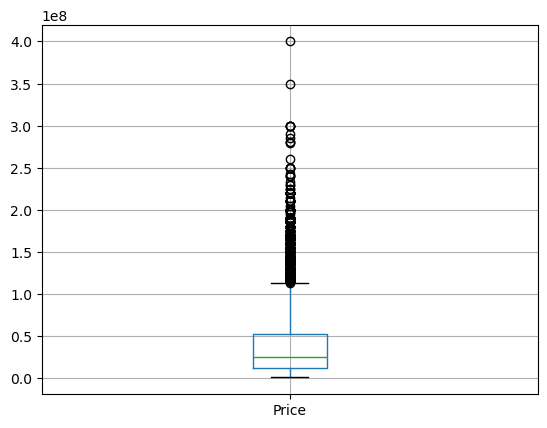

In [20]:
data.boxplot( column= 'Price')
plt.show()

In [21]:
q1 = data["Price"].quantile(0.25)
q3 = data["Price"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 *iqr
lower = q1 - 1.5 * iqr


In [22]:
lower , upper

(np.float64(-47500000.0), np.float64(112500000.0))

In [23]:
(data.Price> upper).sum() , (data.Price< lower).sum()

(np.int64(491), np.int64(0))

In [24]:
#data=data[(data['Price'] >= lower) & (data['Price'] <= upper)]

In [25]:
q1 = data["Price"].quantile(0.25)
q3 = data["Price"].quantile(0.75)
iqr = q3 - q1
upper3 = q3 + 3 *iqr

In [26]:
(data.Price> upper3).sum()

np.int64(115)

In [27]:
data = data[data.Price <=  upper3]

In [28]:
data.shape

(9028, 5)

In [29]:
data.NoOfBathrooms.value_counts()

NoOfBathrooms
3.0     2713
2.0     1969
4.0     1644
6.0     1252
5.0     1044
1.0      178
7.0      134
8.0       74
10.0      10
9.0       10
Name: count, dtype: int64

In [30]:
data.NoOfBedrooms.value_counts()

NoOfBedrooms
3.0     3122
2.0     2116
4.0     1618
5.0      860
6.0      816
1.0      175
7.0      127
8.0      109
9.0       44
10.0      29
11.0      12
Name: count, dtype: int64

In [31]:
data.AreaSqYards.value_counts()

AreaSqYards
120    664
500    579
200    564
240    418
300    306
      ... 
714      1
177      1
299      1
640      1
104      1
Name: count, Length: 370, dtype: int64

In [32]:
# Teeno columns ke liye 3 * IQR limit check karna
for col in ['AreaSqYards', 'NoOfBedrooms', 'NoOfBathrooms']:
    q1 = data[col].quantile(0.25)       # 25% wali value
    q3 = data[col].quantile(0.75)       # 75% wali value
    iqr = q3 - q1                       # beech ke 50% ka phailao
    upper = q3 + 3 * iqr                # upper limit
    lower = q1 - 3 * iqr                #lower limit
    count = (data[col] > upper).sum()   # limit se upar kitni rows
    count1= (data[col] < lower).sum()   # limit se niche kitni rows
    print(col, "| upper:", upper, "| extreme rows:", count, "| lower:", lower, count1)

AreaSqYards | upper: 744.0 | extreme rows: 15 | lower: -348.0 0
NoOfBedrooms | upper: 10.0 | extreme rows: 12 | lower: -4.0 0
NoOfBathrooms | upper: 11.0 | extreme rows: 0 | lower: -3.0 0


In [33]:
data.Address.nunique() 

289

In [34]:
data.Address.value_counts()

Address
other                                                     1024
DHA Phase 6, DHA Defence                                   315
DHA Phase 8, DHA Defence                                   200
DHA Phase 5, DHA Defence                                   161
Askari 5 - Sector J, Askari 5                              145
                                                          ... 
Shah Latif Town, Bin Qasim Town                              2
Saadi Garden, Scheme 33                                      2
Al Amin Society, Malir                                       1
Bahria Town - Precinct 15-A, Bahria Town - Precinct 15       1
Shahmir Residency, University Road                           1
Name: count, Length: 289, dtype: int64

In [35]:
data["Area"] = data.Address.str.split(",").str[-1].str.strip()

C:\Users\User\AppData\Local\Temp\ipykernel_6720\3424734686.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Area"] = data.Address.str.split(",").str[-1].str.strip()


In [36]:
data.Area= data.Area.str.replace(r"\s*-\s*Precinct.*", " ", regex=True)

C:\Users\User\AppData\Local\Temp\ipykernel_6720\3865516323.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.Area= data.Area.str.replace(r"\s*-\s*Precinct.*", " ", regex=True)


In [37]:
data.Area.nunique()

63

In [38]:
data.Area.value_counts()

Area
Karachi                    1189
DHA Defence                1071
other                      1024
Gulistan-e-Jauhar           725
Gulshan-e-Iqbal             607
                           ... 
Scheme 33 - Sector 52-A       4
Mehmoodabad                   3
Faisal Cantonment             3
Scheme 33 - Sector 31         3
Bin Qasim Town                2
Name: count, Length: 63, dtype: int64

In [39]:
counts = data.Area.value_counts()

In [40]:
rare = counts[counts < 20].index

In [41]:
rare

Index(['Scheme 33 - Sector 16-A', 'Korangi', 'Cantt',
       'Federal B Area - Block 8', 'Bahria Paradise', 'Defence View Phase 2',
       'Scheme 33 - Sector 25-A', 'Gulshan-e-Kaneez Fatima', 'Surjani Town',
       'Taiser Town', 'Defence View Society', 'Scheme 33 - Sector 32',
       'Gulistan-e-Jauhar - Block 15', 'Gulshan-e-Maymar - Sector W',
       'DHA City Karachi', 'Scheme 33 - Sector 50', 'Karachi Motorway',
       'Scheme 33 - Sector 20-A', 'Scheme 33 - Sector 51-A',
       'Scheme 33 - Sector 52-A', 'Mehmoodabad', 'Faisal Cantonment',
       'Scheme 33 - Sector 31', 'Bin Qasim Town'],
      dtype='object', name='Area')

In [42]:
data.Area = data.Area.where(~data.Area.isin(rare), 'Rare Area')

C:\Users\User\AppData\Local\Temp\ipykernel_6720\2149620327.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.Area = data.Area.where(~data.Area.isin(rare), 'Rare Area')


In [43]:
data.Area.nunique()

40

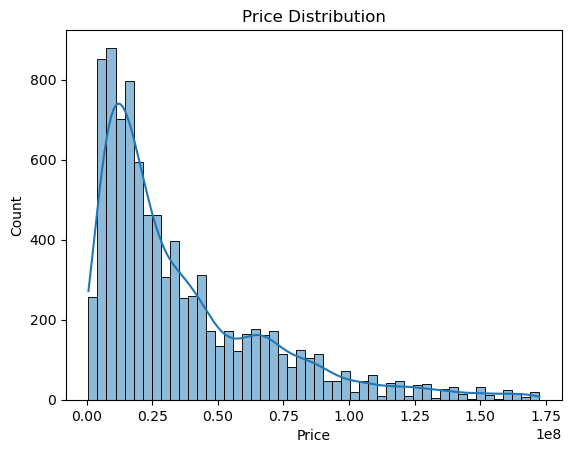

In [44]:
sns.histplot(data.Price, bins=50 , kde = True)
plt.title("Price Distribution")
plt.show()

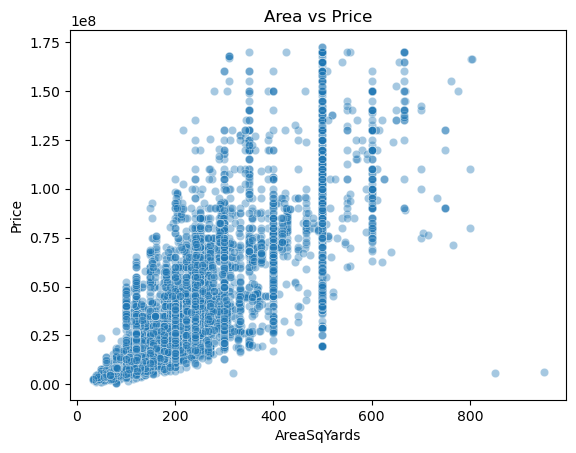

In [45]:
sns.scatterplot(x = data.AreaSqYards , y = data.Price , alpha = 0.4)
plt.title("Area vs Price")
plt.show()

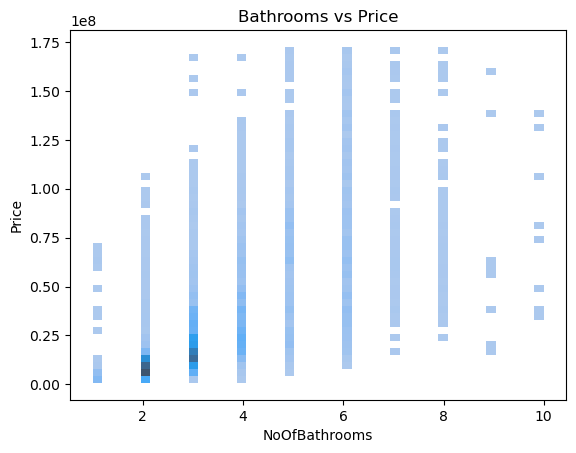

In [46]:
sns.histplot(x = data.NoOfBathrooms , y = data.Price)
plt.title("Bathrooms vs Price")
plt.show()

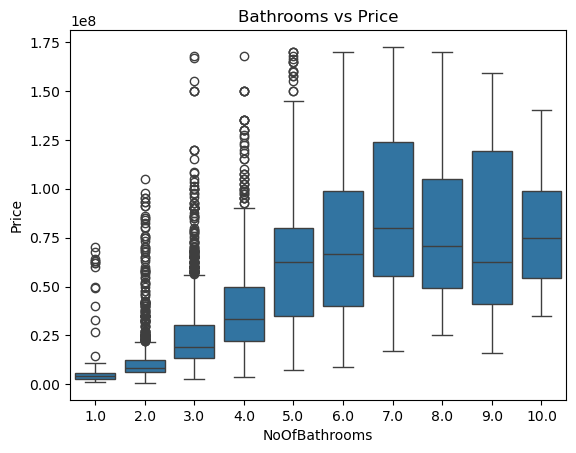

In [47]:
sns.boxplot(x = data.NoOfBathrooms , y = data.Price)
plt.title("Bathrooms vs Price")
plt.show()

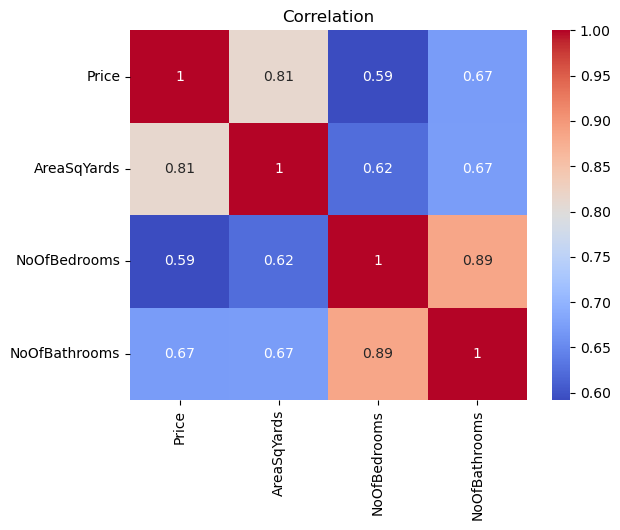

In [48]:
sns.heatmap(data[['Price', 'AreaSqYards', 'NoOfBedrooms', 'NoOfBathrooms']].corr(),
            annot=True, cmap='coolwarm')
plt.title("Correlation")
plt.show()

In [49]:
data = data.drop(columns=["Address"])

In [50]:
data = pd.get_dummies(data , columns=["Area"], drop_first= True, dtype=int)

In [51]:
data

,Price,NoOfBedrooms,NoOfBathrooms,AreaSqYards,Area_Askari 5,Area_Bahria Sports City,Area_Bahria Town,Area_Bahria Town Karachi,Area_Clifton,Area_DHA Defence,...,Area_Saadi Road,Area_Saadi Town,Area_Scheme 33,Area_Scheme 33 - Sector 17-A,Area_Scheme 33 - Sector 18-A,Area_Scheme 33 - Sector 35-A,Area_Shadman,Area_Shah Faisal Town,Area_University Road,Area_other
0,4200000.0,1.0,1.0,60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,5900000.0,2.0,2.0,161,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,42000000.0,5.0,5.0,500,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,37500000.0,3.0,3.0,300,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,21000000.0,4.0,4.0,350,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9138,5500000.0,2.0,2.0,100,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9139,4900000.0,2.0,2.0,67,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9140,4500000.0,2.0,1.0,67,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9141,25000000.0,4.0,4.0,240,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [52]:
X = data.drop("Price", axis = 1)
y = data.Price

In [53]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X, y , random_state=123 , test_size=0.2)

In [54]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [55]:
model.fit(X_train , y_train)

LinearRegression()

In [56]:
y_pred_train = model.predict(X_train)

In [57]:
y_pred_test = model.predict(X_test)

In [58]:
from sklearn.metrics import r2_score , mean_absolute_error , root_mean_squared_error

In [59]:
r2_score(y_train , y_pred_train) , r2_score(y_test, y_pred_test)

(0.793740409525364, 0.7987237022375289)

In [60]:
mean_absolute_error(y_train, y_pred_train) , mean_absolute_error(y_test, y_pred_test)

(10019819.725678632, 10378813.244516436)

In [61]:
root_mean_squared_error(y_train , y_pred_train) , root_mean_squared_error(y_test, y_pred_test)

(14877655.466674516, 15391498.865970789)

In [62]:
from sklearn.tree import DecisionTreeRegressor
model_dt = DecisionTreeRegressor(max_depth=10 , random_state=42)

In [63]:
model_dt.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=10, random_state=42)

In [64]:
y_pred_train_dt = model_dt.predict(X_train)
y_pred_test_dt = model_dt.predict(X_test)

In [65]:
r2_score(y_train, y_pred_train_dt) , r2_score(y_test, y_pred_test_dt)

(0.8770523673772619, 0.8219659638911252)

In [66]:
mean_absolute_error(y_train, y_pred_train_dt) , mean_absolute_error(y_test, y_pred_test_dt)

(7017378.061479006, 8499571.543487096)

In [67]:
root_mean_squared_error(y_train , y_pred_train_dt) , root_mean_squared_error(y_test, y_pred_test_dt)

(11486494.448056063, 14475584.72896326)

In [68]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100 , max_depth=10 , random_state=42)

In [69]:
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, random_state=42)

In [70]:
y_pred_train_rf = rf.predict(X_train)
y_pred_test_rf = rf.predict(X_test)

In [71]:
r2_score(y_train, y_pred_train_rf) , r2_score(y_test, y_pred_test_rf)

(0.8857136786358877, 0.8490822655899338)

In [72]:
mean_absolute_error(y_train, y_pred_train_rf) , mean_absolute_error(y_test, y_pred_test_rf)

(6977658.711266633, 8028559.695943564)

In [73]:
root_mean_squared_error(y_train , y_pred_train_rf) , root_mean_squared_error(y_test, y_pred_test_rf)

(11074510.738359276, 13327685.483032664)

In [74]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

In [75]:
pf = make_pipeline(PolynomialFeatures(degree=2) , LinearRegression())
pf.fit(X_train, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

In [76]:
y_pred_train_pf = pf.predict(X_train)
y_pred_test_pf = pf.predict(X_test)

In [77]:
r2_score(y_train, y_pred_train_pf) , r2_score(y_test, y_pred_test_pf)

(0.8301588383113259, 0.8326044797980807)

In [78]:
mean_absolute_error(y_train, y_pred_train_pf) , mean_absolute_error(y_test, y_pred_test_pf)

(8614268.68480558, 8995127.279944148)

In [79]:
root_mean_squared_error(y_train , y_pred_train_pf) , root_mean_squared_error(y_test, y_pred_test_pf)

(13500470.290902726, 14036425.10045664)

In [80]:
# har feature ki ahmiyat, bade se chhota
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.head(10))

AreaSqYards                        0.775389
NoOfBathrooms                      0.057935
Area_Bahria Town Karachi           0.034210
Area_DHA Phase 8                   0.033939
NoOfBedrooms                       0.025273
Area_DHA Defence                   0.023425
Area_Emaar Crescent Bay            0.010313
Area_Karachi                       0.008387
Area_Navy Housing Scheme Karsaz    0.007476
Area_Gulshan-e-Iqbal Town          0.003257
dtype: float64


In [82]:
house_model = rf

In [84]:
import joblib
joblib.dump(house_model, "house_model.pkl")
joblib.dump(list(X_train.columns), "columns.pkl")

['columns.pkl']

## Conclusion

- **Goal:** Predict house prices in Karachi using area, bedrooms, bathrooms and location.
- **Cleaning:** Removed 7,706 duplicate rows and 115 extreme price outliers.
  Reduced 289 addresses to 40 areas by grouping rare locations.
- **Models compared:** Linear Regression, Polynomial Regression, Decision Tree, Random Forest.
- **Best model:** Random Forest (Test R² = 0.849, MAE ≈ 8.0M PKR).
- **Key finding:** Plot size (AreaSqYards) is the strongest price driver (~77% importance),
  followed by bathrooms and location (Bahria Town, DHA).
- **Limitations:** No data on property age, condition or exact location;
  duplicates could not be verified without listing IDs.